# 05 — Feature Engineering (Week 6)
**Goal:** add new features, re-train the Week 5 models, and measure what each new feature group is worth.

| New feature | How it's built | Technique |
|---|---|---|
| `Age`, `BedBathRatio`, `SqftPerBedroom` | Arithmetic on existing columns | Basic feature engineering |
| `SchoolDistrictPrice` | **Spatial join** of each home's coordinates against the CA School District Areas 2024-25 boundaries, then the district's smoothed average price (training rows only) | GeoPandas, map projections (CRS), point-in-polygon, nearest-polygon fallback |
| `CompsPricePerSqft` | Median price per sq ft of the **10 nearest previous sales**, the way appraisers use "comps" | Nearest-neighbour search with a BallTree on real map distance (haversine), built so a home never sees its own price |

The deliverable is the **feature-set comparison table** in section 5: every model is re-trained on each feature set with the same data, split and settings as Weeks 4–5, so any change in score comes from the features alone.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from sklearn.neighbors import BallTree
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

pd.set_option("display.float_format", "{:,.3f}".format)

TARGET = "ClosePrice"
BASE_NUMERIC = ["LivingArea", "LotSizeSquareFeet", "BedroomsTotal", "BathroomsTotalInteger",
                "YearBuilt", "GarageSpaces", "Stories", "Latitude", "Longitude"]
BINARY = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]

## 1. Load the Week 3 data (same split as Weeks 4–5)

In [2]:
df = pd.read_csv("cleaned_sfr.csv", parse_dates=["CloseDate"], dtype={"PostalCode": str})
print(f"{len(df):,} sales; train = {(df['Split'] == 'train').sum():,}, test = {(df['Split'] == 'test').sum():,}")

296,573 sales; train = 106,696, test = 11,991


## 2. Simple engineered features
* **Age** = sale year − year built. Buyers think in "a 40-year-old house", not "built in 1986".
* **BedBathRatio** = bedrooms ÷ bathrooms. 4 beds with 1 bath is a very different home from 4 beds with 3 baths.
* **SqftPerBedroom** = living area ÷ bedrooms. Separates spacious homes from ones with many small rooms.

None of these use the price, so they can be computed on all rows at once.

In [3]:
df["Age"] = df["CloseDate"].dt.year - df["YearBuilt"]
df["BedBathRatio"] = df["BedroomsTotal"] / df["BathroomsTotalInteger"]
df["SqftPerBedroom"] = df["LivingArea"] / df["BedroomsTotal"]

ENGINEERED = ["Age", "BedBathRatio", "SqftPerBedroom"]
df[ENGINEERED].describe().T[["mean", "50%", "min", "max"]]

,mean,50%,min,max
Age,49.027,49.000,-1.000,172.000
BedBathRatio,1.460,1.500,0.250,7.500
SqftPerBedroom,578.754,540.000,91.750,"8,050.000"


## 3. School districts: spatial join
### 3.1 Load the boundaries
The shapefile has one polygon per district (937 in total). Two things to check before joining:
* **Coordinate system (CRS).** The polygons are in `EPSG:3857` (Web Mercator, units = metres). Our homes are plain latitude/longitude (`EPSG:4326`, units = degrees). The two must use the same CRS, or every point lands in the wrong place.
* **Invalid shapes.** A few polygons cross over themselves, which can make point-in-polygon tests fail. `make_valid()` repairs them.

In [4]:
districts = gpd.read_file("DistrictAreas2425.zip")
print("CRS:", districts.crs, "|", len(districts), "districts")
print("Invalid polygons before repair:", (~districts.geometry.is_valid).sum())
districts["geometry"] = districts.geometry.make_valid()
districts["DistrictTy"].value_counts().to_frame("districts")

CRS: EPSG:3857 | 937 districts
Invalid polygons before repair: 7


,districts
DistrictTy,
Elementary,516
Unified,345
High,76


**Columns deliberately not used.** The file also has each district's student demographics: race/ethnicity percentages, English learners, socioeconomically disadvantaged students, and so on. We use **only the district's identity and boundary**. Using a neighbourhood's racial makeup to price homes is exactly what the **Fair Housing Act** prohibits, and the other demographic columns closely track it. The district itself is fine: buyers do pay for school districts, and the model learns that from sale prices, not from who attends.

In [5]:
districts = districts[["DistrictNa", "DistrictTy", "geometry"]]

### 3.2 Which district is each home in?
California has three district types. A home is usually inside **one Unified district** (K-12), or inside **an Elementary district plus a High school district** that overlap. The district key is:
* the Unified district if there is one, otherwise
* "Elementary / High" (e.g. "Cupertino Union / Fremont Union High").

In [6]:
homes = gpd.GeoDataFrame(df[["ListingKey"]],
                         geometry=gpd.points_from_xy(df["Longitude"], df["Latitude"]),
                         crs="EPSG:4326").to_crs(districts.crs)       # degrees -> same metres as the polygons

hits = gpd.sjoin(homes, districts, how="inner", predicate="within")    # point-in-polygon
by_type = hits.pivot_table(index=hits.index, columns="DistrictTy", values="DistrictNa", aggfunc="first")

district = (by_type["Unified"]
            .fillna(by_type["Elementary"] + " / " + by_type["High"])
            .fillna(by_type["Elementary"])
            .fillna(by_type["High"]))
print(f"Inside a district: {len(district):,} of {len(df):,} homes")

Inside a district: 296,545 of 296,573 homes


A few homes fall **outside every polygon**: on the coastline, or with coordinates slightly off. Instead of dropping them, `sjoin_nearest` assigns the closest district. (Web Mercator stretches distances by about 20% at California's latitude, which is fine for picking the *nearest* polygon.)

In [7]:
outside = homes.loc[~homes.index.isin(district.index)]
nearest = gpd.sjoin_nearest(outside, districts, distance_col="metres")
nearest = nearest[~nearest.index.duplicated()]
print(f"Assigned to nearest district: {len(nearest)} homes, median distance {nearest['metres'].median():,.0f} m")

df["SchoolDistrict"] = pd.concat([district, nearest["DistrictNa"]])
assert df["SchoolDistrict"].notna().all(), "some homes have no district"

match_type = pd.Series("Unified", index=df.index)
match_type[by_type["Unified"].reindex(df.index).isna()] = "Elementary / High"
match_type[nearest.index] = "Nearest (outside all)"
print(f"{df['SchoolDistrict'].nunique():,} distinct district keys")
match_type.value_counts().to_frame("homes")

Assigned to nearest district: 28 homes, median distance 54 m
688 distinct district keys


,homes
Unified,222107
Elementary / High,74438
Nearest (outside all),28


### 3.3 Does the district matter?

In [8]:
by_district = df.groupby("SchoolDistrict")[TARGET].agg(sales="size", median_price="median").query("sales >= 100")
by_district.sort_values("median_price").iloc[[0, 1, 2, -3, -2, -1]]

,sales,median_price
SchoolDistrict,,
Needles Unified,102,"155,000.000"
Palo Verde Unified,197,"240,000.000"
Konocti Unified,389,"267,000.000"
Rancho Santa Fe Elementary / San Dieguito Union High,221,"5,000,000.000"
Hillsborough City Elementary / San Mateo Union High,167,"5,300,000.000"
Beverly Hills Unified,269,"6,500,000.000"


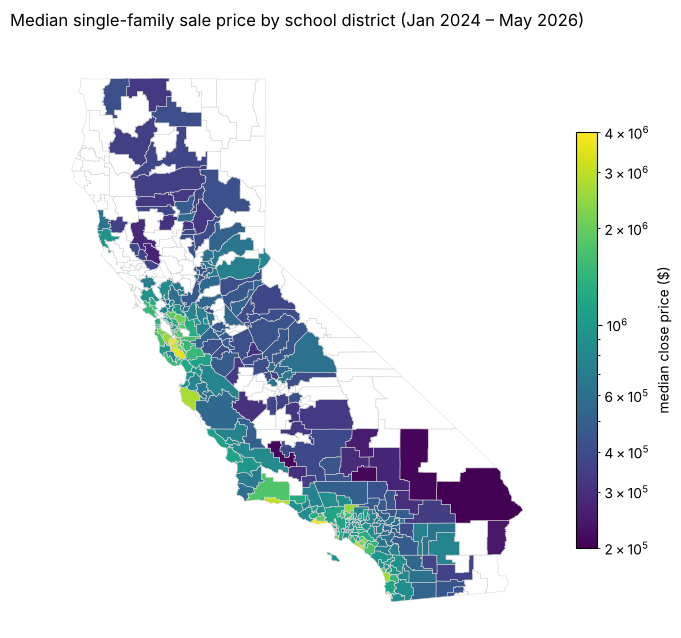

In [9]:
# map: median sale price of each Unified / High school district (one per home)
level = by_type["Unified"].fillna(by_type["High"]).rename("DistrictNa")
prices = df.join(level).groupby("DistrictNa")[TARGET].agg(["median", "size"]).query("size >= 20")
mapped = districts[districts["DistrictTy"] != "Elementary"].merge(prices, left_on="DistrictNa", right_index=True)

fig, ax = plt.subplots(figsize=(8, 9))
districts[districts["DistrictTy"] != "Elementary"].boundary.plot(ax=ax, color="lightgray", linewidth=0.3)
mapped.plot(column="median", ax=ax, cmap="viridis", norm=LogNorm(2e5, 4e6), legend=True,
            legend_kwds={"label": "median close price ($)", "shrink": 0.6})
ax.set_title("Median single-family sale price by school district (Jan 2024 – May 2026)")
ax.set_axis_off(); plt.show()

Prices swing more than 20× between districts, and even within one county neighbouring districts differ sharply. That's the extra detail this layer adds beyond ZIP code and county.

## 4. Nearby comps (extension)
Appraisers price a home by looking at **comparable recent sales nearby**. We build the same thing: for each home, the median log price per sq ft of its **10 nearest training sales**, measured as real distance on the globe (haversine). Multiplied by the home's own size, this is a quick appraiser-style estimate.

**The leakage trap:** when we look up neighbours for a *training* home, the closest "neighbour" is the home itself. If its own price counted, the feature would partly contain the answer. The model would learn to trust it, then fail on the test month, where no home's price is known. So every training home **skips itself**, and test homes only look at training sales.

In [10]:
SMOOTHING = 20     # sales a group needs before its own average outweighs the statewide one
K_COMPS = 10


def smoothed_price(train, test, col):
    """Each group's average log price, pulled toward the overall average when the group is small. Training rows only."""
    log_price = np.log(train[TARGET])
    overall = log_price.mean()
    stats = log_price.groupby(train[col]).agg(["mean", "count"])
    value = (stats["count"] * stats["mean"] + SMOOTHING * overall) / (stats["count"] + SMOOTHING)
    return train[col].map(value), test[col].map(value).fillna(overall)


def comps_price(train, test, k=K_COMPS):
    """Median log price-per-sq-ft of the k nearest TRAINING sales. A training home never counts itself."""
    to_radians = lambda d: np.radians(d[["Latitude", "Longitude"]].to_numpy())
    tree = BallTree(to_radians(train), metric="haversine")
    ppsf = np.log(train[TARGET] / train["LivingArea"]).to_numpy()

    _, idx_train = tree.query(to_radians(train), k=k + 1)
    own = idx_train == np.arange(len(train))[:, None]
    own[~own.any(axis=1), -1] = True           # self not returned (tied with an identical location): drop the farthest
    idx_train = idx_train[~own].reshape(len(train), k)

    _, idx_test = tree.query(to_radians(test), k=k)
    return np.median(ppsf[idx_train], axis=1), np.median(ppsf[idx_test], axis=1)

## 5. Re-train the models on each feature set
`prepare()` is the Week 3 version, extended to take a feature list. As before, every learned value (medians, group prices, comps, scaling) comes from the **training rows only**.

In [11]:
def prepare(train, test, numeric, encode_cols, comps=False):
    X_tr, X_te = pd.DataFrame(index=train.index), pd.DataFrame(index=test.index)

    # median fill + "was missing" flags
    medians = train[numeric].median()
    for col in numeric:
        if train[col].isna().any():
            X_tr[f"{col}_missing"] = train[col].isna().astype(int)
            X_te[f"{col}_missing"] = test[col].isna().astype(int)
        X_tr[col], X_te[col] = train[col].fillna(medians[col]), test[col].fillna(medians[col])
    for col in ["LivingArea", "LotSizeSquareFeet"]:
        X_tr[col], X_te[col] = np.log1p(X_tr[col]), np.log1p(X_te[col])
    for col in BINARY:
        X_tr[col], X_te[col] = train[col], test[col]

    # location-price features, learned from training sales only
    scale_cols = list(numeric)
    for col in encode_cols:
        X_tr[f"{col}Price"], X_te[f"{col}Price"] = smoothed_price(train, test, col)
        scale_cols.append(f"{col}Price")
    if comps:
        X_tr["CompsPricePerSqft"], X_te["CompsPricePerSqft"] = comps_price(train, test)
        scale_cols.append("CompsPricePerSqft")

    # county one-hot: test gets exactly the training columns
    county_tr = pd.get_dummies(train["CountyOrParish"], prefix="CountyOrParish", dtype=int)
    county_te = pd.get_dummies(test["CountyOrParish"], prefix="CountyOrParish", dtype=int).reindex(
        columns=county_tr.columns, fill_value=0)
    X_tr, X_te = X_tr.join(county_tr), X_te.join(county_te)

    scaler = StandardScaler().fit(X_tr[scale_cols])
    X_tr[scale_cols], X_te[scale_cols] = scaler.transform(X_tr[scale_cols]), scaler.transform(X_te[scale_cols])
    return X_tr, X_te, np.log(train[TARGET]), test[TARGET]

In [12]:
train, test = df[df["Split"] == "train"], df[df["Split"] == "test"]

FEATURE_SETS = {
    "A. Week 5 features":       dict(numeric=BASE_NUMERIC, encode_cols=["PostalCode"]),
    "B. A + age & ratios":      dict(numeric=BASE_NUMERIC + ENGINEERED, encode_cols=["PostalCode"]),
    "C. B + school district":   dict(numeric=BASE_NUMERIC + ENGINEERED, encode_cols=["PostalCode", "SchoolDistrict"]),
    "D. C + nearby comps":      dict(numeric=BASE_NUMERIC + ENGINEERED, encode_cols=["PostalCode", "SchoolDistrict"],
                                     comps=True),
}
MODELS = {   # same settings as Week 5, so only the features change
    "Linear Regression": lambda: LinearRegression(),
    "Decision Tree (depth 8)": lambda: DecisionTreeRegressor(max_depth=8, random_state=0),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=100, min_samples_leaf=2, max_features=0.33,
                                                   n_jobs=-1, random_state=0),
}

rows, forests = [], {}
for set_name, spec in FEATURE_SETS.items():
    X_train, X_test, y_train, y_test = prepare(train, test, **spec)
    assert X_train.notna().all().all() and X_test.notna().all().all()
    for model_name, make in MODELS.items():
        model = make().fit(X_train, y_train)
        pred = np.exp(model.predict(X_test))
        rows.append({"feature_set": set_name, "model": model_name, "features": X_train.shape[1],
                     "test_R2": r2_score(y_test, pred),
                     "median_pct_error": np.median(np.abs(pred - y_test) / y_test)})
        if model_name == "Random Forest":
            forests[set_name] = (model, X_train.columns)

results = pd.DataFrame(rows)

### Feature-set comparison: test R² on May 2026

In [13]:
r2_table = results.pivot(index="feature_set", columns="model", values="test_R2")[list(MODELS)]
r2_table.insert(0, "features", results.groupby("feature_set")["features"].first())
r2_table

model,features,Linear Regression,Decision Tree (depth 8),Random Forest
feature_set,,,,
A. Week 5 features,77,0.779,0.794,0.853
B. A + age & ratios,81,0.791,0.793,0.850
C. B + school district,82,0.800,0.797,0.859
D. C + nearby comps,83,0.866,0.844,0.883


### Median % error (the typical miss on a home)

In [14]:
results.pivot(index="feature_set", columns="model", values="median_pct_error")[list(MODELS)]

model,Linear Regression,Decision Tree (depth 8),Random Forest
feature_set,,,
A. Week 5 features,0.121,0.127,0.082
B. A + age & ratios,0.120,0.128,0.084
C. B + school district,0.117,0.125,0.083
D. C + nearby comps,0.098,0.113,0.080


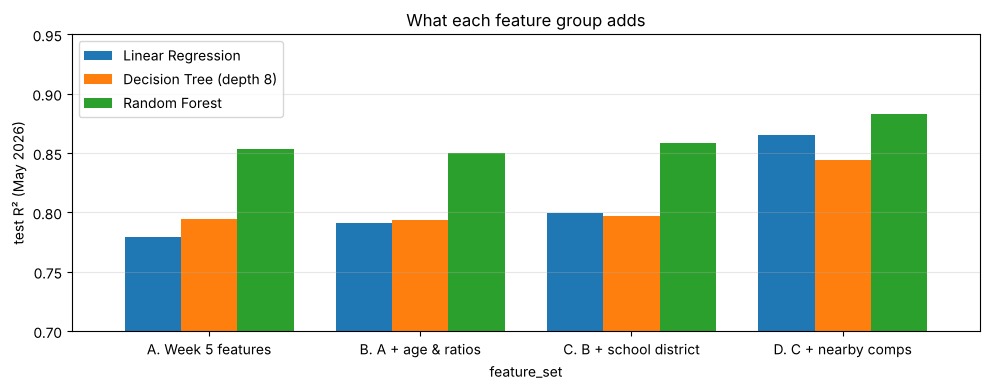

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
r2_table[list(MODELS)].plot.bar(ax=ax, rot=0, width=0.8)
ax.set_ylim(0.7, 0.95); ax.set_ylabel("test R² (May 2026)")
ax.set_title("What each feature group adds"); ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

**Reading the table** (row A reproduces Week 5: 0.779 / 0.794 / 0.853)

| Step | Linear Regression | Random Forest | Why |
|---|---|---|---|
| **A → B: age & ratios** | +0.012 | −0.003 | Linear Regression can't multiply or divide columns itself, so ratios hand it something new. Trees can already split on beds and baths together, so for them the ratios mostly add noise. `Age` is nearly the same as `YearBuilt`, so it adds little to either. |
| **B → C: school district** | +0.009 | +0.009 | Helps both. Districts are a finer location grid than county and often split a ZIP, so they capture what buyers pay for schools. |
| **C → D: nearby comps** | **+0.066** | **+0.024** | The biggest gain. "What did the 10 closest homes sell for, per sq ft" packs the most local price information into one number. Linear Regression gains most because it couldn't build that from raw coordinates. |

* **Best model: Random Forest on feature set D, test R² 0.883** (up from 0.853). With good features, even plain Linear Regression (0.866) now beats last week's Random Forest.
* **Watch the error column, not just R².** The forest's typical error barely moved (8.2% → 8.0%). R² is measured in dollars, so most of its gain came from pricing expensive homes better, where a 10% miss is hundreds of thousands of dollars. Linear Regression improved on both (12.1% → 9.8%).
* **Not every feature helps every model.** That's why we compare feature sets instead of keeping everything by default.

## 6. What the Random Forest uses now
Feature importance for the full feature set (D). County one-hot columns are summed into one row.

In [16]:
model, cols = forests["D. C + nearby comps"]
importance = pd.Series(model.feature_importances_, index=cols)
is_county = importance.index.str.startswith("CountyOrParish_")
importance = pd.concat([importance[~is_county], pd.Series({"County (all one-hot columns)": importance[is_county].sum()})])
importance.sort_values(ascending=False).head(12).to_frame("importance")

,importance
PostalCodePrice,0.328
CompsPricePerSqft,0.223
SchoolDistrictPrice,0.135
LivingArea,0.125
BathroomsTotalInteger,0.063
SqftPerBedroom,0.031
BedroomsTotal,0.018
LotSizeSquareFeet,0.013
Longitude,0.011
Latitude,0.011


The top three are now all location-price features: **ZIP price (0.33), comps (0.22) and school district price (0.14)**, ahead of living area. In Week 5, ZIP price alone carried half the importance. Now that weight is shared, because the three describe location at different scales: ZIP, school district, and the 10 nearest sales. `SqftPerBedroom` is the most useful of the simple ratios.

## 7. Save the data with the new columns

In [17]:
df.to_csv("features_sfr.csv", index=False)
print(f"features_sfr.csv: {len(df):,} rows x {df.shape[1]} columns (adds Age, BedBathRatio, SqftPerBedroom, SchoolDistrict)")

features_sfr.csv: 296,573 rows x 23 columns (adds Age, BedBathRatio, SqftPerBedroom, SchoolDistrict)


`CompsPricePerSqft` and the district/ZIP prices are **not** saved: they depend on which sales are in the training window, so later notebooks rebuild them with `prepare()`.

## Summary
* **New features:** Age, BedBathRatio, SqftPerBedroom; **school district** from a GeoPandas spatial join (EPSG:4326 → 3857, point-in-polygon, nearest-polygon fallback for 28 homes, 688 district keys); **nearby comps** from a haversine BallTree, with each training home excluded from its own neighbours to avoid leakage.
* **Left out on purpose:** the district file's student demographic columns (Fair Housing Act).
* **Results (test R², May 2026):**

| Feature set | Linear Regression | Decision Tree | Random Forest |
|---|---|---|---|
| A. Week 5 features | 0.779 | 0.794 | 0.853 |
| B. + age & ratios | 0.791 | 0.793 | 0.850 |
| C. + school district | 0.800 | 0.797 | 0.859 |
| D. + nearby comps | **0.866** | **0.844** | **0.883** |

* **Takeaway:** location is everything in home prices. The district layer helps, and the comps feature helps most. Week 7 will tune models (gradient boosting, depth, number of trees) on feature set D.